# Predicting Online Shoppers' Purchase Intention Using Machine Learning
## Exploratory Data Analysis (EDA)

**Research question:** How effectively can supervised machine learning models predict whether an online shopping session results in a purchase, and how does excluding PageValues affect predictive performance?

**Dataset:** Online Shoppers Purchasing Intention Dataset (Sakar & Kastro, 2018), UCI Machine Learning Repository, dataset id 468.

**Task:** Supervised binary classification. Target = `Revenue` (TRUE = purchase).

**Scope of this notebook:** data verification and exploratory analysis only. No models are trained here.

**Environment:** install dependencies first with `pip install -r requirements.txt`.

## 1. Setup

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42  # used in later modelling notebooks; recorded here for reproducibility

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.1.1 | numpy 2.5.4 | seaborn 0.13.2


## 2. Load the Data

The data are downloaded directly from UCI with `ucimlrepo`, so no data file is stored in the repository.

In [19]:
dataset = fetch_ucirepo(id=468)

X = dataset.data.features
y = dataset.data.targets
df = pd.concat([X, y], axis=1)

print("Dataset dimensions:", df.shape)
assert df.shape == (12330, 18), "Unexpected shape - check the UCI download"
df.head()

Dataset dimensions: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Data Structure and Variable Types

Several integer columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are **category codes**, not quantities. They are treated as categorical, so their means and Pearson correlations are not meaningful.

In [20]:
target = "Revenue"

count_features = ["Administrative", "Informational", "ProductRelated"]
duration_features = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
rate_features = ["BounceRates", "ExitRates", "PageValues", "SpecialDay"]
numerical_features = count_features + duration_features + rate_features

categorical_features = ["Month", "OperatingSystems", "Browser", "Region",
                        "TrafficType", "VisitorType", "Weekend"]

# Every predictor must be assigned to exactly one group
assert set(numerical_features + categorical_features) == set(df.columns) - {target}
print(f"{len(numerical_features)} numerical + {len(categorical_features)} categorical = "
      f"{len(numerical_features) + len(categorical_features)} predictors")

df.info()

10 numerical + 7 categorical = 17 predictors
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  i

In [21]:
# Levels of the categorical variables
for col in categorical_features:
    print(f"{col}: {df[col].nunique()} levels -> {sorted(df[col].astype(str).unique())}")

Month: 10 levels -> ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
OperatingSystems: 8 levels -> ['1', '2', '3', '4', '5', '6', '7', '8']
Browser: 13 levels -> ['1', '10', '11', '12', '13', '2', '3', '4', '5', '6', '7', '8', '9']
Region: 9 levels -> ['1', '2', '3', '4', '5', '6', '7', '8', '9']
TrafficType: 20 levels -> ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '3', '4', '5', '6', '7', '8', '9']
VisitorType: 3 levels -> ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend: 2 levels -> ['False', 'True']


**Interpretation:** `Month` has 10 levels. January and April do not appear, and June is spelled `June` while the other months use three-letter abbreviations. This does not affect encoding, but the month order must be set manually when plotting. The code variables have 8 (`OperatingSystems`), 13 (`Browser`), 9 (`Region`) and 20 (`TrafficType`) levels, so one-hot encoding will add a moderate number of columns.

## 4. Data Quality: Missing Values and Duplicates

In [22]:
missing = df.isnull().sum()
print("Total missing values:", int(missing.sum()))

dup_count = df.duplicated().sum()                 # repeats after the first occurrence
dup_rows = df[df.duplicated(keep=False)]          # every row that belongs to a duplicate group
n_groups = dup_rows.astype(str).drop_duplicates().shape[0]

print("Duplicate rows (after first occurrence):", dup_count)
print("Rows involved in duplicate groups:", len(dup_rows))
print("Number of distinct duplicate groups:", n_groups)
print("\nRevenue among duplicated rows:")
print(dup_rows[target].value_counts())

Total missing values: 0
Duplicate rows (after first occurrence): 125
Rows involved in duplicate groups: 201
Number of distinct duplicate groups: 76

Revenue among duplicated rows:
Revenue
False    201
Name: count, dtype: int64


In [23]:
# What do the duplicated sessions look like?
dup_rows[numerical_features].describe().T[["mean", "min", "max"]].round(3)

,mean,min,max
Administrative,0.000,0.0,0.0
Informational,0.000,0.0,0.0
ProductRelated,1.060,1.0,2.0
Administrative_Duration,0.000,0.0,0.0
Informational_Duration,0.000,0.0,0.0
ProductRelated_Duration,0.000,0.0,0.0
BounceRates,0.200,0.2,0.2
ExitRates,0.200,0.2,0.2
PageValues,0.000,0.0,0.0
SpecialDay,0.014,0.0,0.8


**Interpretation:** No values are missing, so no imputation is required. There are 125 duplicate rows in 76 distinct groups (201 rows in total), and all of them are non-purchase sessions. The summary shows that every duplicated session is a minimal bounce session: 1-2 product pages, zero duration on every page type, BounceRates and ExitRates both 0.2, and PageValues 0. Sessions this short can genuinely occur more than once, so the rows are **kept** in the main analysis. A secondary sensitivity analysis will remove them. If they are removed, it must be done **before** the train/test split so that identical rows cannot appear in both sets.

## 5. Target Variable: Purchase vs No Purchase

,Sessions,Percent
No Purchase,10422,84.53
Purchase,1908,15.47


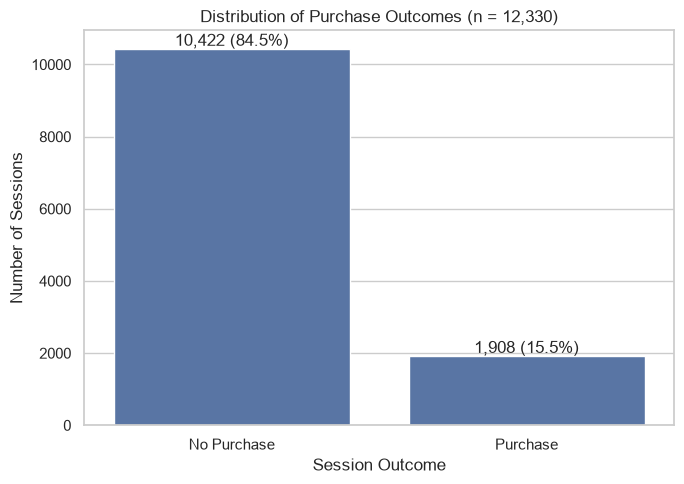

Imbalance ratio: 5.46 non-purchases per purchase
A model that always predicts 'No Purchase' would score 84.53% accuracy


In [24]:
counts = df[target].value_counts().sort_index()
pct = df[target].value_counts(normalize=True).sort_index() * 100
target_table = pd.DataFrame({"Sessions": counts, "Percent": pct.round(2)})
target_table.index = ["No Purchase", "Purchase"]
display(target_table)

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x=target, order=[False, True], ax=ax)
ax.set_xticks([0, 1], ["No Purchase", "Purchase"])
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:,} ({p:.1f}%)" for v, p in zip(counts, pct)])
ax.set_title("Distribution of Purchase Outcomes (n = 12,330)")
ax.set_xlabel("Session Outcome")
ax.set_ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

print(f"Imbalance ratio: {counts[False] / counts[True]:.2f} non-purchases per purchase")
print(f"A model that always predicts 'No Purchase' would score {pct[False]:.2f}% accuracy")

**Interpretation:** About 84.5% of sessions are non-purchases and 15.5% are purchases. A trivial majority-class model would reach about 84.5% accuracy while finding no buyers. This supports using **PR-AUC** as the primary metric, with precision, recall, F1, ROC-AUC and the confusion matrix as supporting measures. It also supports a **stratified** train/test split and stratified cross-validation.

## 6. Numerical Features by Purchase Outcome

Only true numerical features are compared here. Medians are reported alongside means because page counts and durations are heavily right-skewed.

In [25]:
summary = df.groupby(target)[numerical_features].agg(["median", "mean"]).T.round(3)
summary.columns = ["No Purchase", "Purchase"]
display(summary)

No Purchase  Purchase
Administrative          median        0.000     2.000
                        mean          2.118     3.394
Informational           median        0.000     0.000
                        mean          0.452     0.786
ProductRelated          median       16.000    29.000
                        mean         28.715    48.210
Administrative_Duration median        0.000    52.367
                        mean         73.740   119.483
Informational_Duration  median        0.000     0.000
                        mean         30.236    57.611
ProductRelated_Duration median      510.190  1109.906
                        mean       1069.988  1876.210
BounceRates             median        0.004     0.000
                        mean          0.025     0.005
ExitRates               median        0.029     0.016
                        mean          0.047     0.020
PageValues              median        0.000    16.758
                        mean          1.976    27.265
SpecialDay              median        0.000     0.000
                        mean          0.068     0.023

In [26]:
skew = df[numerical_features].skew().sort_values(ascending=False).round(2)
zero_share = (df[numerical_features] == 0).mean().mul(100).round(1)
display(pd.DataFrame({"Skewness": skew, "% zeros": zero_share}))

,Skewness,% zeros
Administrative,1.96,46.8
Administrative_Duration,5.62,47.9
BounceRates,2.95,44.8
ExitRates,2.15,0.6
Informational,4.04,78.7
Informational_Duration,7.58,80.5
PageValues,6.38,77.9
ProductRelated,4.34,0.3
ProductRelated_Duration,7.26,6.1
SpecialDay,3.30,89.9


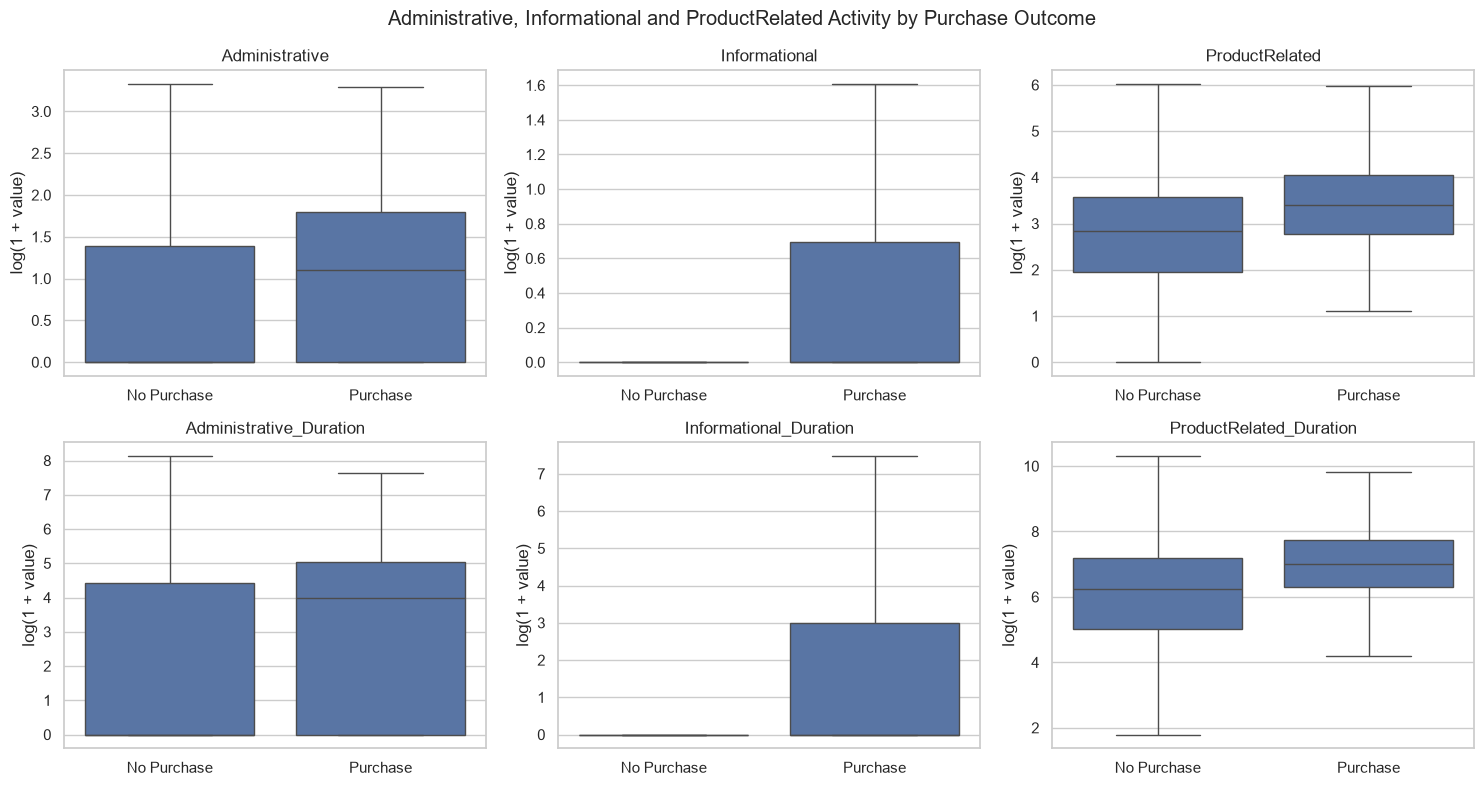

In [27]:
# Page activity and duration: log scale because of heavy skew (log1p keeps zeros)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), count_features + duration_features):
    sns.boxplot(data=df, x=target, y=np.log1p(df[col]), order=[False, True], ax=ax, showfliers=False)
    ax.set_xticks([0, 1], ["No Purchase", "Purchase"])
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("log(1 + value)")
fig.suptitle("Administrative, Informational and ProductRelated Activity by Purchase Outcome")
plt.tight_layout()
plt.show()

**Interpretation:** Purchasing sessions involve more browsing. Compared with non-purchase sessions, their median is higher for Administrative pages (2 vs 0), Administrative_Duration (52.4 vs 0 seconds), ProductRelated pages (29 vs 16) and ProductRelated_Duration (1,109.9 vs 510.2 seconds). The median for Informational pages is 0 in both groups, because 78.7% of all sessions view no informational pages. Every count and duration feature is strongly right-skewed (skewness 1.96 to 7.58), and several are mostly zeros. This supports a `log1p` transformation and scaling for Logistic Regression and SVM. These are associations, not causes: longer browsing does not necessarily cause purchasing.

### 6.1 BounceRates and ExitRates

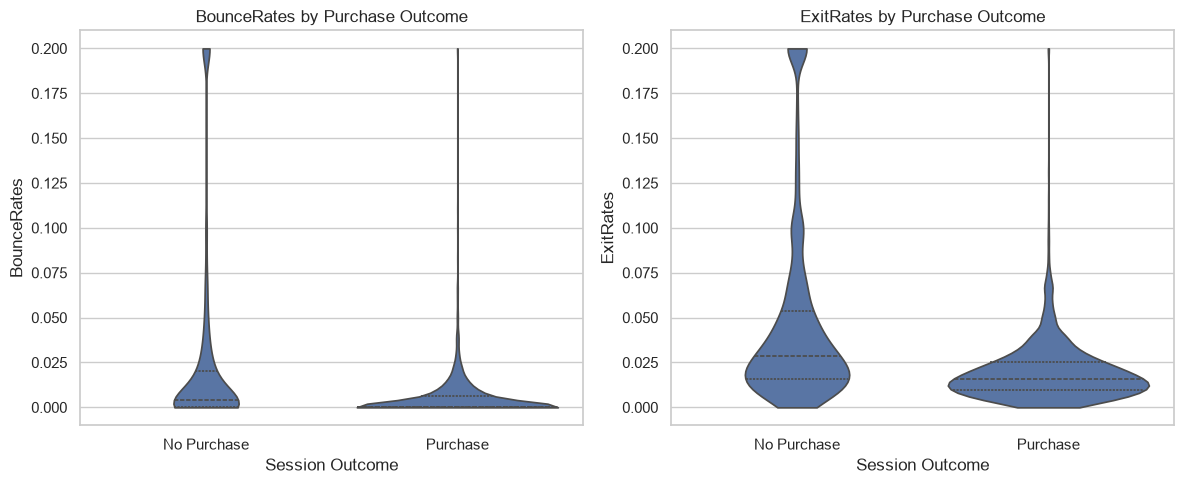

Correlation between BounceRates and ExitRates (Spearman): 0.602


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["BounceRates", "ExitRates"]):
    sns.violinplot(data=df, x=target, y=col, order=[False, True], ax=ax, cut=0, inner="quartile")
    ax.set_xticks([0, 1], ["No Purchase", "Purchase"])
    ax.set_title(f"{col} by Purchase Outcome")
    ax.set_xlabel("Session Outcome")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

print("Correlation between BounceRates and ExitRates (Spearman):",
      round(df["BounceRates"].corr(df["ExitRates"], method="spearman"), 3))

**Interpretation:** Purchasing sessions have lower bounce and exit rates. Median BounceRates is 0.000 vs 0.004 and median ExitRates is 0.016 vs 0.029, with means of 0.005 vs 0.025 and 0.020 vs 0.047. The two rates are moderately correlated (Spearman rho = 0.602), so they share some information without being redundant. Both are kept, but Logistic Regression coefficients for them should be interpreted with care.

## 7. PageValues and Potential Leakage

In the UCI documentation, PageValues is the average value of the pages a user visited before completing an e-commerce transaction. Because it is linked to the transaction, it may only be fully known late in a session or after it. This section measures how strongly it separates the classes, to motivate the planned **with/without PageValues ablation**.

In [29]:
print(df.groupby(target)["PageValues"].describe().round(3))

pv_positive = df["PageValues"] > 0
pv_table = pd.crosstab(pv_positive.rename("PageValues > 0"), df[target], margins=True)
display(pv_table)

rate = df.groupby(pv_positive)[target].mean().mul(100).round(2)
print(f"Purchase rate when PageValues = 0: {rate[False]}%")
print(f"Purchase rate when PageValues > 0: {rate[True]}%")
print(f"Share of purchases with PageValues > 0: {pv_positive[df[target]].mean() * 100:.2f}%")

           count    mean     std  min    25%     50%     75%      max
Revenue                                                              
False    10422.0   1.976   9.072  0.0  0.000   0.000   0.000  246.759
True      1908.0  27.265  35.192  0.0  3.641  16.758  38.898  361.764


Revenue,False,True,All
PageValues > 0,,,
False,9230,370,9600
True,1192,1538,2730
All,10422,1908,12330


Purchase rate when PageValues = 0: 3.85%
Purchase rate when PageValues > 0: 56.34%
Share of purchases with PageValues > 0: 80.61%


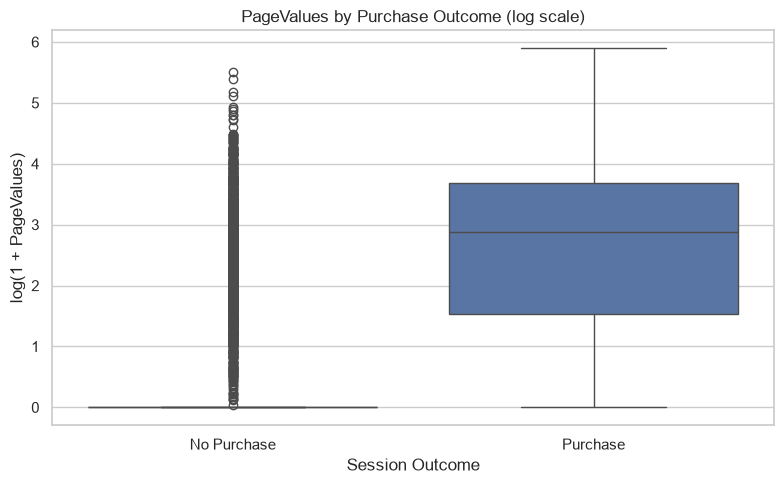

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x=target, y=np.log1p(df["PageValues"]), order=[False, True], ax=ax)
ax.set_xticks([0, 1], ["No Purchase", "Purchase"])
ax.set_title("PageValues by Purchase Outcome (log scale)")
ax.set_xlabel("Session Outcome")
ax.set_ylabel("log(1 + PageValues)")
plt.tight_layout()
plt.show()

**Interpretation:** PageValues is the single most class-separating feature. It is 0 for at least 75% of non-purchase sessions (median and 75th percentile both 0), while purchase sessions have a median of 16.76. Only 3.85% of sessions with PageValues = 0 end in a purchase, compared with 56.34% of sessions with PageValues > 0, and 80.61% of all purchases have a positive PageValue. However, 370 purchases have PageValues = 0, so the feature does not determine the outcome perfectly.

This is a **prediction-time concern** rather than proof of leakage: the value depends on pages reached during the session, so it is unsuitable for early-session prediction. The modelling phase will therefore train every model **with and without PageValues** on the same split.

## 8. Categorical Features and Purchase Rates


VisitorType


,Sessions,Purchases,Purchase rate (%)
VisitorType,,,
New_Visitor,1694,422,24.91
Other,85,16,18.82
Returning_Visitor,10551,1470,13.93



Month


,Sessions,Purchases,Purchase rate (%)
Month,,,
Feb,184,3,1.63
Mar,1907,192,10.07
May,3364,365,10.85
June,288,29,10.07
Jul,432,66,15.28
Aug,433,76,17.55
Sep,448,86,19.20
Oct,549,115,20.95
Nov,2998,760,25.35



Weekend


,Sessions,Purchases,Purchase rate (%)
Weekend,,,
False,9462,1409,14.89
True,2868,499,17.40



SpecialDay


,Sessions,Purchases,Purchase rate (%)
SpecialDay,,,
0.0,11079,1831,16.53
0.2,178,14,7.87
0.4,243,13,5.35
0.6,351,29,8.26
0.8,325,11,3.38
1.0,154,10,6.49


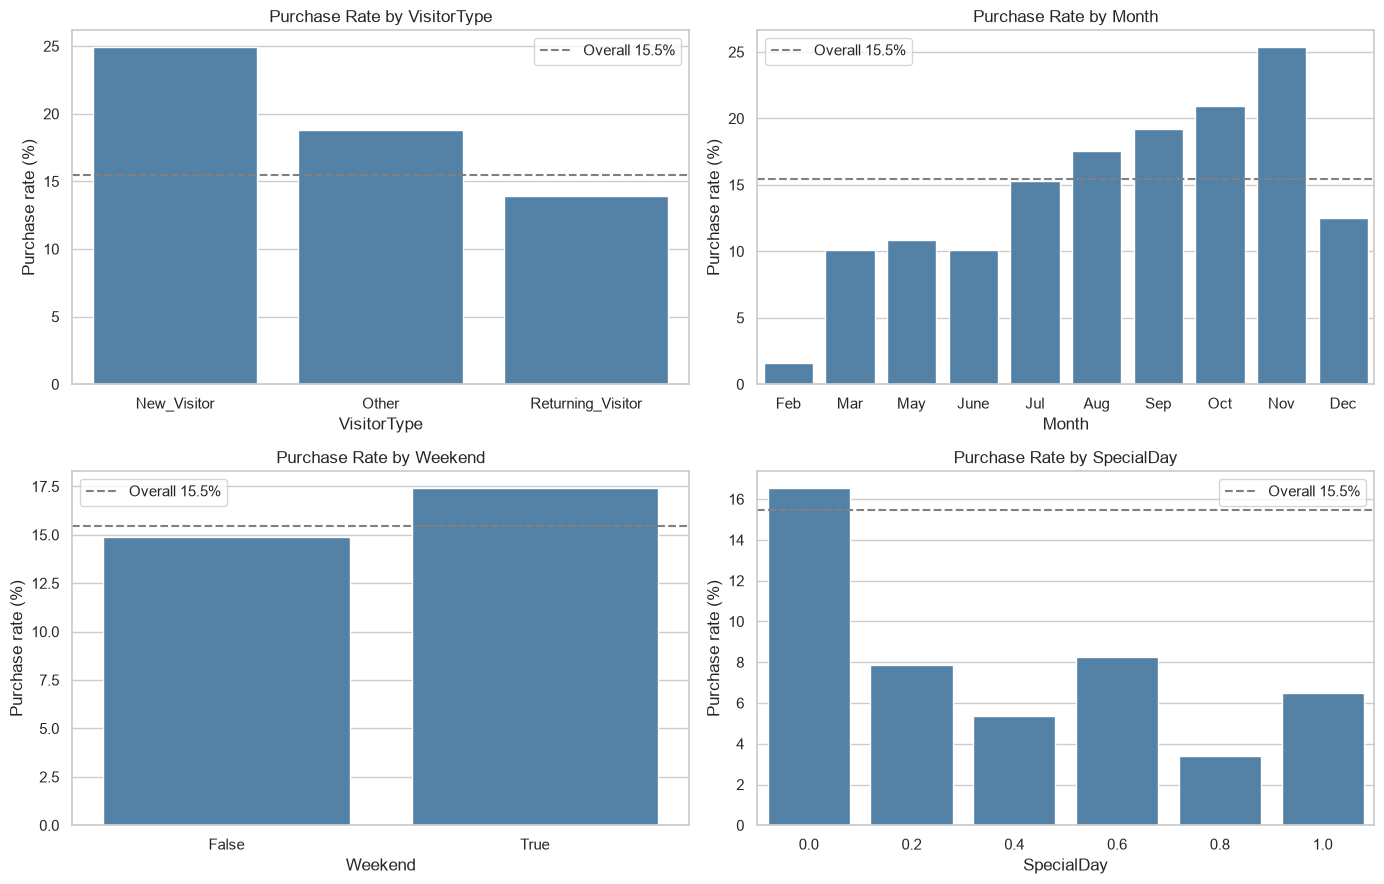

In [31]:
def purchase_rate(col):
    t = df.groupby(col)[target].agg(Sessions="size", Purchases="sum")
    t["Purchase rate (%)"] = (t["Purchases"] / t["Sessions"] * 100).round(2)
    return t

month_order = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
overall = df[target].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ["VisitorType", "Month", "Weekend", "SpecialDay"]):
    t = purchase_rate(col)
    if col == "Month":
        t = t.loc[[m for m in month_order if m in t.index]]
    print(f"\n{col}"); display(t)
    sns.barplot(x=t.index.astype(str), y=t["Purchase rate (%)"], ax=ax, color="steelblue")
    ax.axhline(overall, ls="--", color="grey", label=f"Overall {overall:.1f}%")
    ax.set_title(f"Purchase Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Purchase rate (%)")
    ax.legend()
plt.tight_layout()
plt.show()

In [32]:
# TrafficType: many levels, some very small -> show size so rare levels are not over-interpreted
display(purchase_rate("TrafficType").sort_values("Sessions", ascending=False))

,Sessions,Purchases,Purchase rate (%)
TrafficType,,,
2,3913,847,21.65
1,2451,262,10.69
3,2052,180,8.77
4,1069,165,15.43
13,738,43,5.83
10,450,90,20.00
6,444,53,11.94
8,343,95,27.70
5,260,56,21.54


**Interpretation:**
- **VisitorType:** New visitors have the highest purchase rate (24.91%), then Other (18.82%) and Returning visitors (13.93%). The Other group has only 85 sessions, so its rate is less reliable.
- **Month:** Purchase rates vary widely, from 1.63% in February (184 sessions) to 25.35% in November (2,998 sessions). November and May are the busiest months, but May converts at only 10.85%.
- **Weekend:** Weekend sessions convert slightly more often (17.40% vs 14.89%).
- **SpecialDay:** Sessions on or near a special day convert *less* often (3.38%-8.26%) than ordinary days (16.53%), but 89.9% of sessions have SpecialDay = 0, so the non-zero groups are small.
- **TrafficType:** Rates range from 0% to 33%, but several types have very few sessions (e.g. types 12, 16, 17 and 18 have 10 or fewer). Rare levels should be grouped into an "Other" category before one-hot encoding to avoid unstable estimates.

## 9. Correlation Analysis

Spearman correlation is used because most numerical features are skewed and zero-inflated. Category-code columns are excluded. The last column shows each feature's correlation with the target.

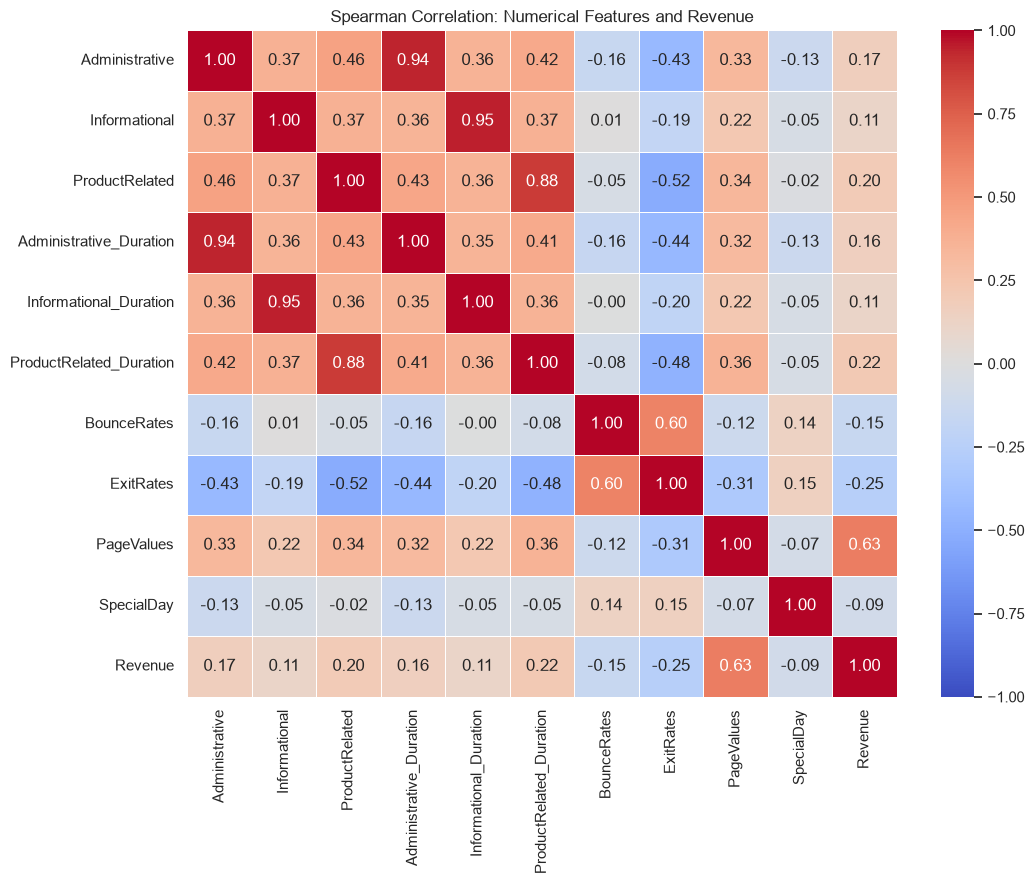

Feature pairs with |rho| >= 0.7:
 Informational   Informational_Duration     0.951
Administrative  Administrative_Duration    0.941
ProductRelated  ProductRelated_Duration    0.883
dtype: float64

Correlation with Revenue:
 PageValues                 0.626
ProductRelated_Duration    0.217
ProductRelated             0.199
Administrative             0.168
Administrative_Duration    0.164
Informational              0.114
Informational_Duration     0.112
SpecialDay                -0.087
BounceRates               -0.149
ExitRates                 -0.254
Name: Revenue, dtype: float64


In [33]:
corr_df = df[numerical_features].assign(Revenue=df[target].astype(int))
corr = corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Spearman Correlation: Numerical Features and Revenue")
plt.tight_layout()
plt.show()

high = (corr.drop(index="Revenue", columns="Revenue")
            .where(np.triu(np.ones((len(numerical_features),) * 2, dtype=bool), k=1))
            .stack().loc[lambda s: s.abs() >= 0.7].sort_values(ascending=False))
print("Feature pairs with |rho| >= 0.7:\n", high.round(3))
print("\nCorrelation with Revenue:\n", corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))

**Interpretation:** Each page count is strongly correlated with its own duration: Informational (rho = 0.951), Administrative (0.941) and ProductRelated (0.883). Each pair largely measures the same behaviour, which matters for Logistic Regression and for interpreting feature importance. PageValues has by far the strongest association with Revenue (rho = 0.626), followed by ProductRelated_Duration (0.217) and ProductRelated (0.199). ExitRates (-0.254) and BounceRates (-0.149) are negatively associated with purchasing. Because PageValues dominates, the ablation is needed to see how well the models perform on browsing behaviour alone. Correlation shows association only. It does not show that a feature causes purchasing.

## 10. Implications for Machine Learning

| Area | Decision based on this EDA |
|---|---|
| Target encoding | `Revenue` -> 1 (purchase) / 0 (no purchase) |
| Categorical encoding | One-hot encode `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`; `Weekend` -> 0/1 |
| Scaling | StandardScaler on numerical features for Logistic Regression and SVM. Consider `log1p` for skewed counts/durations. Tree models need no scaling |
| Imbalance | Stratified split and CV; compare `class_weight="balanced"` against no weighting, applied inside training folds only |
| Leakage | All preprocessing inside a scikit-learn `Pipeline`, fitted on training folds only; test set used once |
| PageValues | Ablation: every model trained with and without PageValues on the same split |
| Duplicates | Keep in main analysis; sensitivity run with duplicates removed before splitting |
| Split / CV | 80/20 stratified split, `random_state=42`; stratified 5-fold CV on the training set |
| Primary metric | PR-AUC; also precision, recall, F1, ROC-AUC, confusion matrix; threshold chosen in CV |

In [34]:
# Prepare inputs for the modelling notebook (no model training here)
y_encoded = df[target].astype(int)
X_full = df.drop(columns=target)
X_no_pagevalues = X_full.drop(columns="PageValues")

print("Target encoding check:", y_encoded.value_counts().to_dict())
print("Full feature set:", X_full.shape, "| Without PageValues:", X_no_pagevalues.shape)

Target encoding check: {0: 10422, 1: 1908}
Full feature set: (12330, 17) | Without PageValues: (12330, 16)


## 11. Summary of EDA Findings

1. The dataset matches the UCI description: 12,330 sessions, 17 predictors and a binary target, with no missing values.
2. 125 duplicate rows (76 groups) exist. All are minimal, zero-duration bounce sessions labelled non-purchase. They are retained, and a sensitivity analysis will remove them.
3. The target is imbalanced (84.53% vs 15.47%, a 5.46:1 ratio), so a majority-class model would reach 84.53% accuracy while finding no buyers. PR-AUC is therefore the primary metric.
4. Purchasing sessions show higher median administrative and product-related activity and lower bounce and exit rates. Count and duration features are heavily right-skewed.
5. PageValues separates the classes far more strongly than any other feature (Spearman rho = 0.626 with Revenue; purchase rate 56.34% when positive vs 3.85% when zero), which motivates the planned ablation.
6. New visitors convert more often than returning visitors (24.91% vs 13.93%), and November has the highest monthly purchase rate (25.35%).
7. Each page count is strongly correlated with its duration (rho 0.88-0.95), and several TrafficType levels are rare and may need grouping.

These findings describe associations in one historical dataset. They do not establish causes of purchasing behaviour.